# Defense Gene Score vs Bacterial Load (Plates 1–5, Recalled Species)

Species-level version of `Recall_genera_update_paper_results/defense_score_vs_bacterial_load_within_sample.ipynb` (itself an update of `Local_analysis/Followup_analyses_after_Luke_talk/Immunity_and_defense_score/top_genes_correlation_with_bacterial_load_within_sample.ipynb`).

Species come from `Oct_2026_recalled_species/lic16s_species_relabund.csv`. Taxa that couldn't be resolved to species keep a higher-rank label in the `Species` column (e.g. `g__Janthinobacterium_571130 Genus`, `f__SbA1 Family`) and are treated as one species each, as unresolved genera were in the genus table. Species under 0.05% of a sample (`AbundR == 0`) are dropped, which matches the cleaning of the recalled-genera table.

- **Transcriptome and defense genes:** unchanged from the genus version (plates 1–5, the 148-gene list from `load_correlated_immunity_genes_plates_1_to_5.ipynb`).
- **Microbiome:** seasonal plant samples only. Species abundances are converted to percent of each sample's total, as in the genus version.
- **Rare taxa:** total abundance of rare species (present in < 10% of seasonal plant samples).
- **Output CSVs:** the exports for Luke stay commented out.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()

metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]

long_term_transcriptome = trimmed_transcriptome.loc[
    trimmed_metadata["Experiment Type"] == "Long Term"
]
long_term_metadata = trimmed_metadata.loc[
    trimmed_metadata["Experiment Type"] == "Long Term"
]

total_load_df = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv",
    index_col=0,
)
long_term_metadata_w_load_info = long_term_metadata.merge(
    total_load_df[["ham16s", "giitsreads", "hamits"]],
    left_on="sampID",
    right_index=True,
    how="left",
)

defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
print("Long-term transcriptomes:", len(long_term_transcriptome))
print("Defense genes:", len(defense_gene_list))

Dropped 6 transcriptomes with < 250,000 total reads
Long-term transcriptomes: 223
Defense genes: 148


In [3]:
transcriptome_in_defense_gene_list = long_term_transcriptome.loc[
    :, long_term_transcriptome.columns.isin(defense_gene_list["gene"])
]
print("Defense genes in transcriptome:", transcriptome_in_defense_gene_list.shape[1])

# Average z score across the defense genes (summed z scores / number of genes)
summed_zscored_transcriptome = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)
long_term_metadata_w_load_info = long_term_metadata_w_load_info.merge(
    summed_zscored_transcriptome.rename("Summed Defense Z Score"),
    left_index=True,
    right_index=True,
)

Defense genes in transcriptome: 148


## Recalled-species microbiome

In [4]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0, which
### includes the zero rows) are dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
long_term_microbiome = microbiome_abundance.loc[
    (microbiome_abundance["sample.type"] == "plant")
    & (microbiome_abundance["seascirc"] == "seasonal")
]

# Sample x species abundance (% of each sample's total), absent species = 0
species_abundance_matrix = pd.pivot_table(
    long_term_microbiome,
    values="Abundance",
    index="Sample",
    columns="Species",
    aggfunc="sum",
    fill_value=0,
)
species_abundance_matrix = (
    species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
)
all_present_species = species_abundance_matrix.columns

# Long format with timepoint, as species_sum_w_tp in the original
sample_timepoint = long_term_microbiome.groupby("Sample")["timepoint"].first()
species_sum_w_tp = (
    species_abundance_matrix.stack()
    .rename("Abundance")
    .reset_index()
    .rename(columns={"Sample": "sampID"})
)
species_sum_w_tp["timepoint"] = species_sum_w_tp["sampID"].map(sample_timepoint)

print("Microbiome samples:", species_abundance_matrix.shape[0])
print("Species:", species_abundance_matrix.shape[1])

Microbiome samples: 224
Species: 609


In [5]:
plotting_df = long_term_metadata_w_load_info[
    [
        "sampID",
        "timepoint",
        "ham16s",
        "Summed Defense Z Score",
        "Experiment Type",
    ]
]
# Add one abundance column per species (inner join: samples with both
# a transcriptome and a microbiome profile)
plotting_df = plotting_df.merge(
    species_abundance_matrix.add_suffix("_Abund"),
    left_on="sampID",
    right_index=True,
)
print("Samples with transcriptome + microbiome:", len(plotting_df))
plotting_df

Samples with transcriptome + microbiome: 223


,sampID,timepoint,ham16s,Summed Defense Z Score,Experiment Type,c__Bacteroidia Class_Abund,c__Dehalococcoidia Class_Abund,f__Bryobacteraceae Family_Abund,f__Burkholderiaceae_A_595421 Family_Abund,f__Gaiellaceae Family_Abund,...,s__WQYW01 sp009781045_Abund,s__Weizmannia coagulans_Abund,s__Weizmannia ginsengihumi_Abund,s__Williamsia_A deligens_Abund,s__Williamsia_A herbipolensis_Abund,s__Williamsia_B muralis_Abund,s__X156 sp004006015_Abund,s__Xenophilus aerolatus_Abund,s__Z2-YC6860 sp001579845_Abund,s__Zeimonas sp001724855_Abund
filename,,,,,,,,,,,,,,,,,,,,,
A2450525897_n01_LICRNA01_A01,LIC001,t01,0.242587,1.231359,Long Term,0.0,0.000000,0.094263,0.785528,0.0,...,0.0,0.0,0.0,0.098752,0.0,0.0,0.0,0.0,0.0,0.0
A2450525897_n01_LICRNA01_B01,LIC002,t01,0.367494,0.729948,Long Term,0.0,0.148844,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
A2450525897_n01_LICRNA01_C01,LIC003,t01,0.507472,2.085132,Long Term,0.0,0.000000,0.000000,1.137002,0.0,...,0.0,0.0,0.0,0.072715,0.0,0.0,0.0,0.0,0.0,0.0
A2450525897_n01_LICRNA01_E01,LIC005,t01,0.594141,0.522025,Long Term,0.0,0.000000,0.000000,0.235902,0.0,...,0.0,0.0,0.0,0.131993,0.0,0.0,0.0,0.0,0.0,0.0
A2450525897_n01_LICRNA01_F01,LIC006,t01,1.089759,2.325064,Long Term,0.0,0.000000,0.000000,0.159732,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A2534491401_n01_LICRNA05_G11,LIC055,t05,0.597918,0.894328,Long Term,0.0,0.000000,0.000000,0.234689,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
A2534491401_n01_LICRNA05_H11,LIC015,t02,0.446507,1.668522,Long Term,0.0,0.000000,0.000000,0.339155,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
A2534491401_n01_LICRNA05_A12,LIC295,t25,0.089415,-0.553658,Long Term,0.0,0.000000,0.000000,6.742486,0.0,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
plotting_df["Rank Within Timepoint"] = plotting_df.groupby("timepoint")["ham16s"].rank()
plotting_df["Zscore within Timepoint"] = plotting_df.groupby("timepoint")[
    "ham16s"
].transform(lambda x: zscore(x))

## Defense score vs load within timepoint

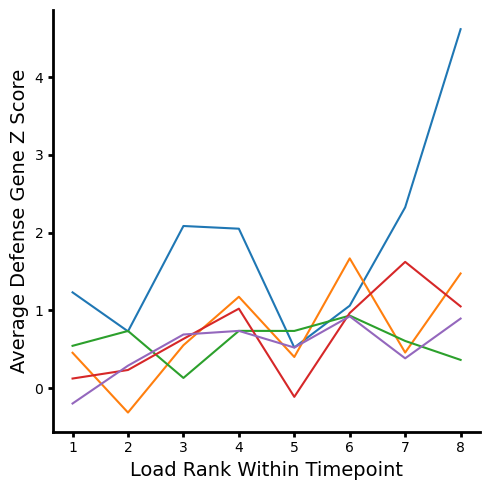

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.lineplot(
    data=plotting_df[
        plotting_df["timepoint"].isin(["t01", "t02", "t03", "t04", "t05"])
    ],
    x="Rank Within Timepoint",
    y="Summed Defense Z Score",
    hue="timepoint",
)
plt.xlabel("Load Rank Within Timepoint", fontsize=14)
plt.ylabel("Average Defense Gene Z Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.get_legend().remove()
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

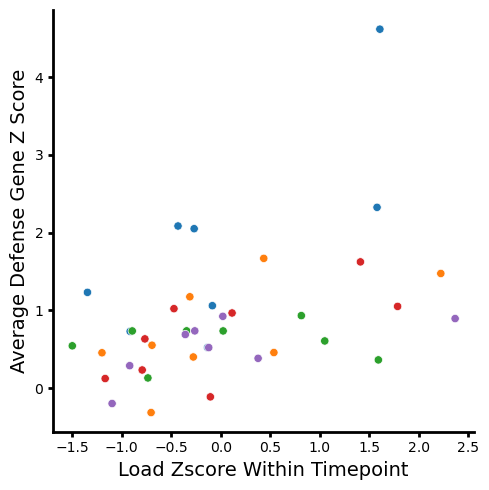

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.scatterplot(
    data=plotting_df[
        plotting_df["timepoint"].isin(["t01", "t02", "t03", "t04", "t05"])
    ],
    x="Zscore within Timepoint",
    y="Summed Defense Z Score",
    hue="timepoint",
)
plt.xlabel("Load Zscore Within Timepoint", fontsize=14)
plt.ylabel("Average Defense Gene Z Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.get_legend().remove()
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

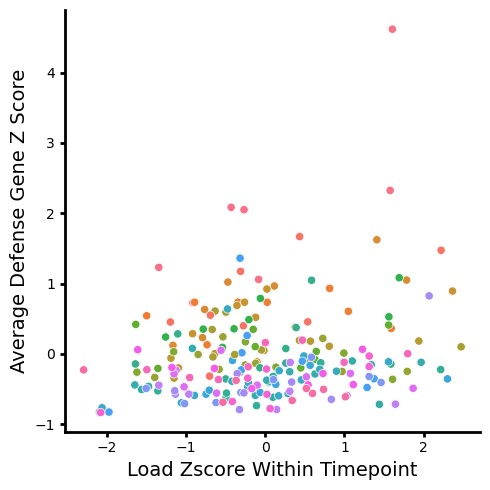

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.scatterplot(
    data=plotting_df[plotting_df["Experiment Type"] == "Long Term"],
    x="Zscore within Timepoint",
    y="Summed Defense Z Score",
    hue="timepoint",
)
plt.xlabel("Load Zscore Within Timepoint", fontsize=14)
plt.ylabel("Average Defense Gene Z Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.get_legend().remove()
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

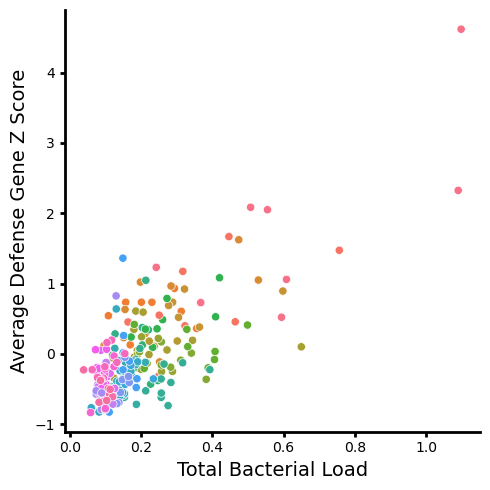

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.scatterplot(
    data=plotting_df[plotting_df["Experiment Type"] == "Long Term"],
    x="ham16s",
    y="Summed Defense Z Score",
    hue="timepoint",
)
plt.xlabel("Total Bacterial Load", fontsize=14)
plt.ylabel("Average Defense Gene Z Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.get_legend().remove()
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()

## Species abundance vs defense score

In [11]:
abund_cols = [col for col in plotting_df.columns if col.endswith("_Abund")]
correlation_df = pd.DataFrame(
    {
        "Column": abund_cols,
        "Correlation_with_Summed_Defense_Z_Score": [
            plotting_df["Summed Defense Z Score"].corr(plotting_df[col])
            for col in abund_cols
        ],
    }
).sort_values("Correlation_with_Summed_Defense_Z_Score", ascending=False)

correlation_df.head(20)

/Users/michael/miniconda3/envs/Luke_terrace/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/michael/miniconda3/envs/Luke_terrace/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Column,Correlation_with_Summed_Defense_Z_Score
534,s__Sphingomonas_L_486704 olei_Abund,0.473856
527,s__Sphingomonas_L_486704 elodea_Abund,0.458435
320,s__Methylobacterium radiotolerans_Abund,0.392404
209,s__Curtobacterium sp001422205_Abund,0.376928
143,s__Aureimonas_A_501548 ureilytica_A_Abund,0.373949
496,s__Rhizobium_C_501058 metallidurans_Abund,0.330500
113,s__Alsobacter soli_Abund,0.318212
335,s__Microbacterium_A_383321 testaceum_F_Abund,0.313153
247,s__Friedmanniella luteola_Abund,0.296883
550,s__Sphingomonas_L_486704 yunnanensis_Abund,0.293108


Top 3 taxa: ['s__Sphingomonas_L_486704 olei', 's__Sphingomonas_L_486704 elodea', 's__Methylobacterium radiotolerans']
Bottom 3 taxa: ['f__Burkholderiaceae_A_595421 Family', 'g__Limnohabitans_A Genus', 's__Kordiimonas sp002401685']


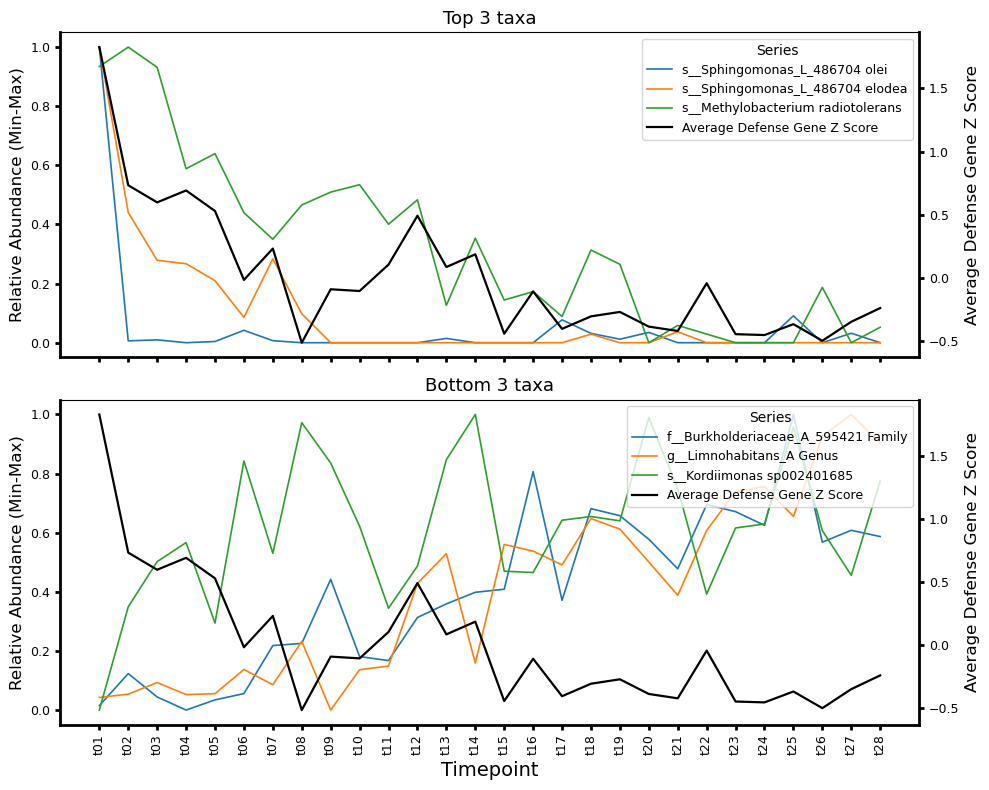

In [12]:
from matplotlib.lines import Line2D

# Drop NaN correlations and exclude selected taxa
excluded_taxa = ["Marihabitans", "Alsobacter"]
correlation_df_filtered = correlation_df.dropna(
    subset=["Correlation_with_Summed_Defense_Z_Score"]
)
excluded_pattern = "|".join(excluded_taxa)
correlation_df_filtered = correlation_df_filtered[
    ~correlation_df_filtered["Column"].str.contains(
        excluded_pattern, case=False, na=False
    )
]

# Select top 3 and bottom 3 taxa by correlation
top_3 = correlation_df_filtered.head(3)["Column"].tolist()
bottom_3 = correlation_df_filtered.tail(3)["Column"].tolist()
selected_abundance_cols = top_3 + bottom_3

# Prepare timepoint-level dataframe
line_df = plotting_df[
    ["timepoint", "Summed Defense Z Score"] + selected_abundance_cols
].copy()
line_df = line_df.groupby("timepoint", as_index=False).mean(numeric_only=True)
line_df["timepoint"] = pd.Categorical(
    line_df["timepoint"],
    categories=sorted(line_df["timepoint"].unique()),
    ordered=True,
)
line_df = line_df.sort_values("timepoint")

# Long-form abundance dataframe and min-max normalization by taxa
abundance_df = line_df.melt(
    id_vars="timepoint",
    value_vars=selected_abundance_cols,
    var_name="Series",
    value_name="Relative Abundance",
)
abundance_df["Series"] = abundance_df["Series"].str.replace("_Abund", "", regex=False)
abundance_df["Relative Abundance (Min-Max)"] = abundance_df.groupby("Series")[
    "Relative Abundance"
].transform(
    lambda values: (
        (values - values.min()) / (values.max() - values.min())
        if values.max() != values.min()
        else 0.0
    )
)

top_names = [col.replace("_Abund", "") for col in top_3]
bottom_names = [col.replace("_Abund", "") for col in bottom_3]

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.patch.set_facecolor("white")

for ax_left, taxa_names, title in [
    (axes[0], top_names, "Top 3 taxa"),
    (axes[1], bottom_names, "Bottom 3 taxa"),
]:
    subset_df = abundance_df[abundance_df["Series"].isin(taxa_names)]

    # Left axis: normalized relative abundance
    sns.lineplot(
        data=subset_df,
        x="timepoint",
        y="Relative Abundance (Min-Max)",
        hue="Series",
        linewidth=1.2,
        ax=ax_left,
    )
    ax_left.set_ylabel("Relative Abundance (Min-Max)", fontsize=12)
    ax_left.set_title(title, fontsize=13)
    ax_left.spines["bottom"].set_color("black")
    ax_left.spines["bottom"].set_linewidth(2)
    ax_left.spines["left"].set_color("black")
    ax_left.spines["left"].set_linewidth(2)
    ax_left.tick_params(axis="both", width=2, labelsize=9)

    # Right axis: summed defense z score
    ax_right = ax_left.twinx()
    sns.lineplot(
        data=line_df,
        x="timepoint",
        y="Summed Defense Z Score",
        color="black",
        linewidth=1.6,
        label="_nolegend_",
        ax=ax_right,
    )
    ax_right.set_ylabel("Average Defense Gene Z Score", fontsize=12)
    ax_right.spines["right"].set_color("black")
    ax_right.spines["right"].set_linewidth(2)
    ax_right.tick_params(axis="y", width=2, labelsize=9)

    # Legend with a single summed defense entry
    handles_left, labels_left = ax_left.get_legend_handles_labels()
    filtered_pairs = [
        (handle, label)
        for handle, label in zip(handles_left, labels_left)
        if label != "Series"
    ]
    left_handles = [handle for handle, _ in filtered_pairs]
    left_labels = [label for _, label in filtered_pairs]
    defense_handle = Line2D([0], [0], color="black", linewidth=1.6)
    ax_left.legend(
        left_handles + [defense_handle],
        left_labels + ["Average Defense Gene Z Score"],
        title="Series",
        loc="upper right",
        fontsize=9,
    )

    sns.despine(ax=ax_left, right=False)

axes[1].set_xlabel("Timepoint", fontsize=14)
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()

print("Top 3 taxa:", top_names)
print("Bottom 3 taxa:", bottom_names)

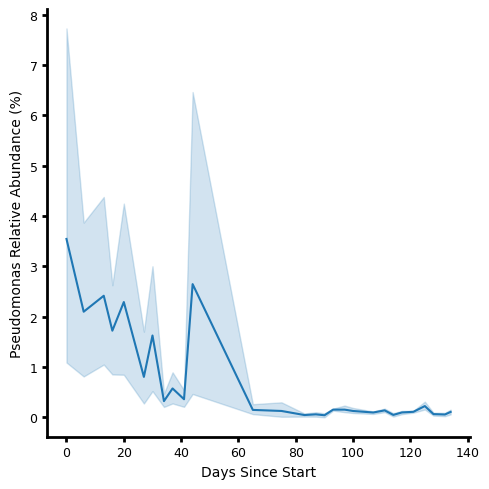

In [13]:
# Original plotted the genus Pseudomonas_B_650453; its species in the recalled
# species table is Pseudomonas_B_650453 oryzihabitans_E
target_species = "s__Pseudomonas_B_650453 oryzihabitans_E"
target_species_plot_df = species_sum_w_tp.loc[
    species_sum_w_tp["Species"] == target_species, ["sampID", "Abundance"]
]
target_species_plot_df = target_species_plot_df.merge(
    long_term_metadata[["sampID", "daysincestart"]],
    on="sampID",
    how="left",
).dropna(subset=["daysincestart"])

fig, ax = plt.subplots(figsize=(5, 5), dpi=100)
fig.patch.set_facecolor("white")
ax = sns.lineplot(
    data=target_species_plot_df.sort_values("daysincestart"),
    x="daysincestart",
    y="Abundance",
    errorbar=("ci", 95),
    color="#1f77b4",
)
plt.ylabel("Pseudomonas Relative Abundance (%)", fontsize=10)
plt.xlabel("Days Since Start", fontsize=10)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()

In [14]:
correlation_df_filtered.head(50)

,Column,Correlation_with_Summed_Defense_Z_Score
534,s__Sphingomonas_L_486704 olei_Abund,0.473856
527,s__Sphingomonas_L_486704 elodea_Abund,0.458435
320,s__Methylobacterium radiotolerans_Abund,0.392404
209,s__Curtobacterium sp001422205_Abund,0.376928
143,s__Aureimonas_A_501548 ureilytica_A_Abund,0.373949
496,s__Rhizobium_C_501058 metallidurans_Abund,0.330500
335,s__Microbacterium_A_383321 testaceum_F_Abund,0.313153
247,s__Friedmanniella luteola_Abund,0.296883
550,s__Sphingomonas_L_486704 yunnanensis_Abund,0.293108
460,s__Pseudomonas_E_647464 silesiensis_Abund,0.287124


In [15]:
# plotting_df.rename(
#     columns={
#         "timepoint": "Timepoint",
#         "Summed Defense Z Score": "Average Defense Z Score",
#     }
# ).to_csv(
#     "/Users/michael/Data/Luke_terrace_experiment/Output_for_Luke/For_talk/full_long_term_metadata_plates_1_to_5_recalled_species.csv",
#     index=False,
# )
# line_df[["timepoint", "Summed Defense Z Score"]].rename(
#     columns={
#         "timepoint": "Timepoint",
#         "Summed Defense Z Score": "Average Defense Z Score, Averaged Across Samples in Timepoint",
#     }
# ).to_csv(
#     "/Users/michael/Data/Luke_terrace_experiment/Output_for_Luke/For_talk/timepoint_summed_defense_z_scores_plates_1_to_5.csv",
#     index=False,
# )
# abundance_df.rename(
#     columns={
#         "Series": "Species",
#         "Relative Abundance (Min-Max)": "Relative Abundance (Min-Max Normalized)",
#     }
# ).to_csv(
#     "/Users/michael/Data/Luke_terrace_experiment/Output_for_Luke/For_talk/top_and_bottom_3_taxa_abundance_corr_recalled_species.csv",
#     index=False,
# )

Number of samples in histogram: 223


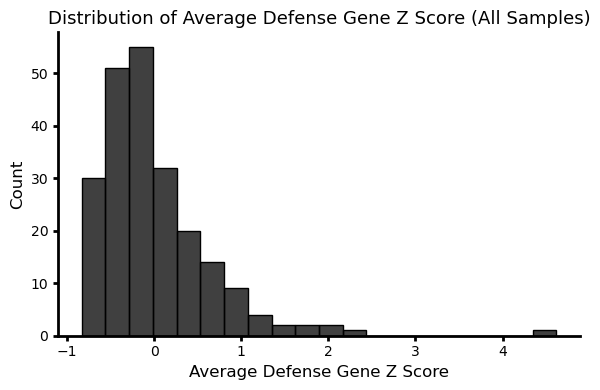

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor("white")

hist_data = plotting_df["Summed Defense Z Score"].dropna()
sns.histplot(hist_data, bins=20, color="black", ax=ax)

plt.xlabel("Average Defense Gene Z Score", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.title("Distribution of Average Defense Gene Z Score (All Samples)", fontsize=13)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2, labelsize=10)
plt.tight_layout()

print(f"Number of samples in histogram: {hist_data.shape[0]}")

## Rare species total abundance

Rare species are those present in fewer than 10% of seasonal plant samples, the same definition as `core_and_rare_species_definitions_and_temporal_patterns.ipynb`.

Rare species: 388


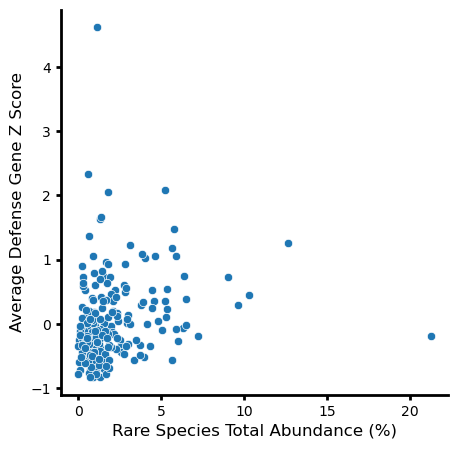

In [17]:
species_prevalence = (species_abundance_matrix > 0).mean()
rare_species = species_prevalence.index[species_prevalence < 0.10]
print(f"Rare species: {len(rare_species)}")

plotting_df_added_info = plotting_df.assign(
    rare_species_total_abund=plotting_df["sampID"].map(
        species_abundance_matrix[rare_species].sum(axis=1)
    )
)

fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
sns.scatterplot(
    data=plotting_df_added_info,
    x="rare_species_total_abund",
    y="Summed Defense Z Score",
    #    hue="timepoint",
    ax=ax,
)
plt.xlabel("Rare Species Total Abundance (%)", fontsize=12)
plt.ylabel("Average Defense Gene Z Score", fontsize=12)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2, labelsize=10)
# sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

## Early (before t14) vs late (t14 onward) species correlations

In [18]:
def species_correlations(df, minimum_present_samples=7):
    """Correlation of each species with the defense score, using only the samples
    where that species is present."""
    rows = []
    for col in [c for c in df.columns if c.endswith("_Abund")]:
        present_mask = df[col].fillna(0) > 0
        n_present_samples = int(present_mask.sum())
        if n_present_samples < minimum_present_samples:
            continue
        filtered_df = df.loc[present_mask, ["Summed Defense Z Score", col]].dropna()
        rows.append(
            {
                "Column": col,
                "Present_Sample_Count": n_present_samples,
                "Correlation_with_Summed_Defense_Z_Score": filtered_df[
                    "Summed Defense Z Score"
                ].corr(filtered_df[col]),
            }
        )
    return pd.DataFrame(rows).sort_values(
        "Correlation_with_Summed_Defense_Z_Score", ascending=False
    )


timepoint_number = plotting_df["timepoint"].str.extract(r"(\d+)")[0].astype(int)
correlation_df_t14_onward = species_correlations(plotting_df.loc[timepoint_number >= 14])
correlation_df_pre_t14 = species_correlations(plotting_df.loc[timepoint_number < 14])
correlation_df_t14_onward

,Column,Present_Sample_Count,Correlation_with_Summed_Defense_Z_Score
137,s__Motilibacter_A deserti_Abund,8,0.826998
1,f__Bryobacteraceae Family_Abund,10,0.824348
77,s__Curtobacterium sp001422205_Abund,11,0.744702
13,g__Leifsonia_A_381664 Genus_Abund,7,0.724121
145,s__Nakamurella multipartita_Abund,7,0.719807
...,...,...,...
232,s__UBA4416 sp002420145_Abund,7,-0.442920
238,s__Virgisporangium myanmarense_Abund,12,-0.463150
7,g__Flavobacterium Genus_Abund,9,-0.470432
68,s__Caulobacter henricii_Abund,10,-0.500744


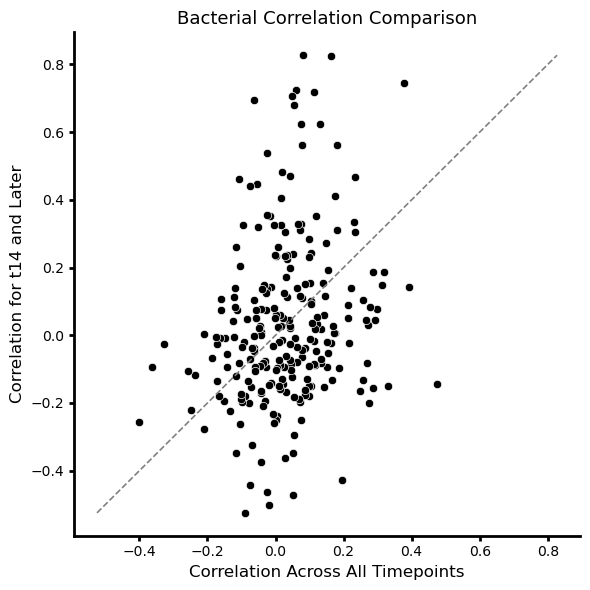

Correlation between the two: 0.208


,Column,Correlation_with_Summed_Defense_Z_Score_All_Timepoints,Correlation_with_Summed_Defense_Z_Score_T14_Onward,Present_Sample_Count
0,s__Sphingomonas_L_486704 olei_Abund,0.473856,-0.142526,20
1,s__Methylobacterium radiotolerans_Abund,0.392404,0.143425,27
2,s__Curtobacterium sp001422205_Abund,0.376928,0.744702,11
3,s__Rhizobium_C_501058 metallidurans_Abund,0.330500,-0.150019,18
4,s__Alsobacter soli_Abund,0.318212,0.187411,48
...,...,...,...,...
235,s__Sphingomonas_L_486704 sp001423845_Abund,-0.249103,-0.222021,117
236,s__Sphingomonas_L_486704 sp001421785_Abund,-0.255735,-0.106996,94
237,f__Burkholderiaceae_A_595421 Family_Abund,-0.326998,-0.025294,119
238,g__Limnohabitans_A Genus_Abund,-0.362561,-0.093701,119


In [19]:
def plot_correlation_comparison(period_df, suffix, ylabel, title):
    comparison_df = correlation_df[
        ["Column", "Correlation_with_Summed_Defense_Z_Score"]
    ].merge(
        period_df[
            [
                "Column",
                "Correlation_with_Summed_Defense_Z_Score",
                "Present_Sample_Count",
            ]
        ],
        on="Column",
        suffixes=("_All_Timepoints", suffix),
        how="inner",
    )
    x_col = "Correlation_with_Summed_Defense_Z_Score_All_Timepoints"
    y_col = f"Correlation_with_Summed_Defense_Z_Score{suffix}"
    comparison_df = comparison_df.dropna(subset=[x_col, y_col])

    fig, ax = plt.subplots(figsize=(6, 6))
    fig.patch.set_facecolor("white")
    sns.scatterplot(data=comparison_df, x=x_col, y=y_col, color="black", ax=ax)
    min_corr = comparison_df[[x_col, y_col]].min().min()
    max_corr = comparison_df[[x_col, y_col]].max().max()
    ax.plot(
        [min_corr, max_corr],
        [min_corr, max_corr],
        linestyle="dashed",
        color="gray",
        linewidth=1.2,
    )
    plt.xlabel("Correlation Across All Timepoints", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.title(title, fontsize=13)
    sns.despine()
    ax.spines["bottom"].set_color("black")
    ax.spines["bottom"].set_linewidth(2)
    ax.spines["left"].set_color("black")
    ax.spines["left"].set_linewidth(2)
    ax.tick_params(axis="both", width=2, labelsize=10)
    plt.tight_layout()
    plt.show()

    print(
        f"Correlation between the two: {comparison_df[x_col].corr(comparison_df[y_col]):.3f}"
    )
    return comparison_df


correlation_comparison_df = plot_correlation_comparison(
    correlation_df_t14_onward,
    "_T14_Onward",
    "Correlation for t14 and Later",
    "Bacterial Correlation Comparison",
)
correlation_comparison_df

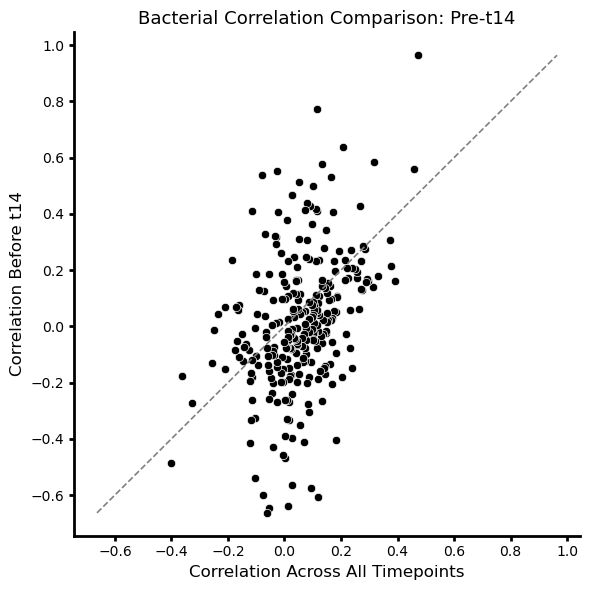

Correlation between the two: 0.385


,Column,Correlation_with_Summed_Defense_Z_Score_All_Timepoints,Correlation_with_Summed_Defense_Z_Score_Pre_T14,Present_Sample_Count
0,s__Sphingomonas_L_486704 olei_Abund,0.473856,0.964073,10
1,s__Sphingomonas_L_486704 elodea_Abund,0.458435,0.561018,30
2,s__Methylobacterium radiotolerans_Abund,0.392404,0.162542,84
3,s__Curtobacterium sp001422205_Abund,0.376928,0.214781,31
4,s__Aureimonas_A_501548 ureilytica_A_Abund,0.373949,0.307020,11
...,...,...,...,...
276,s__Sphingomonas_L_486704 sp001423845_Abund,-0.249103,-0.011384,87
277,s__Sphingomonas_L_486704 sp001421785_Abund,-0.255735,-0.131150,37
278,f__Burkholderiaceae_A_595421 Family_Abund,-0.326998,-0.272807,102
279,g__Limnohabitans_A Genus_Abund,-0.362561,-0.175048,103


In [20]:
correlation_comparison_pre_t14_df = plot_correlation_comparison(
    correlation_df_pre_t14,
    "_Pre_T14",
    "Correlation Before t14",
    "Bacterial Correlation Comparison: Pre-t14",
)
correlation_comparison_pre_t14_df

## Defense score spread per timepoint

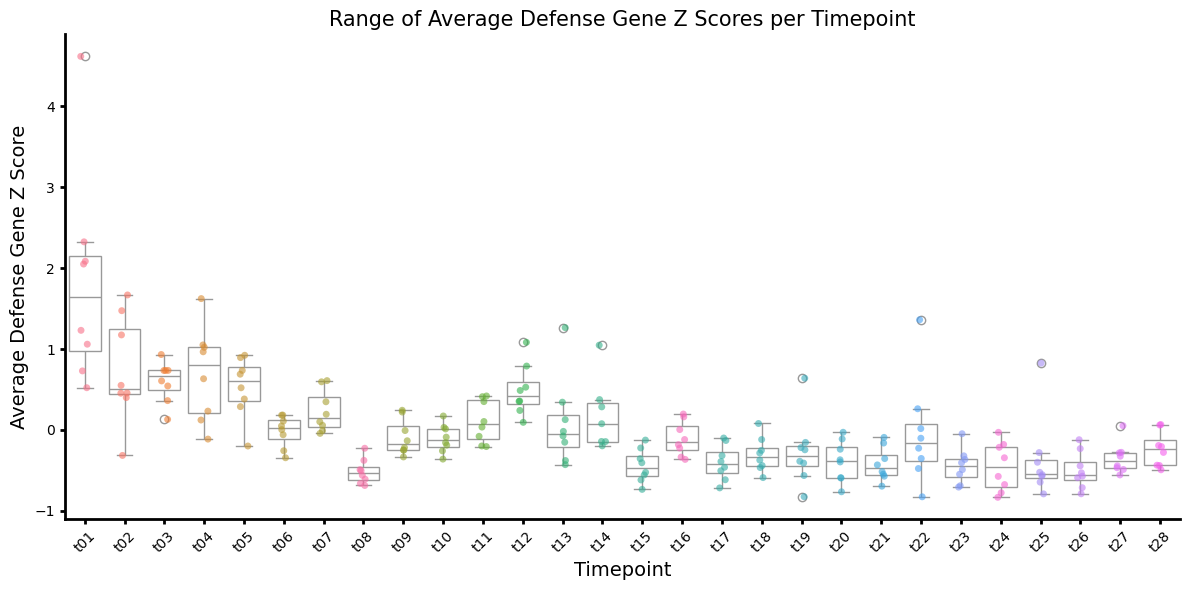

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("white")

sorted_timepoints = sorted(plotting_df["timepoint"].unique())

sns.boxplot(
    data=plotting_df,
    x="timepoint",
    y="Summed Defense Z Score",
    order=sorted_timepoints,
    ax=ax,
    color="white",
)
sns.stripplot(
    data=plotting_df,
    x="timepoint",
    y="Summed Defense Z Score",
    order=sorted_timepoints,
    alpha=0.6,
    ax=ax,
    hue="timepoint",
    legend=False,
)

plt.xlabel("Timepoint", fontsize=14)
plt.ylabel("Average Defense Gene Z Score", fontsize=14)
plt.title("Range of Average Defense Gene Z Scores per Timepoint", fontsize=15)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2, labelsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

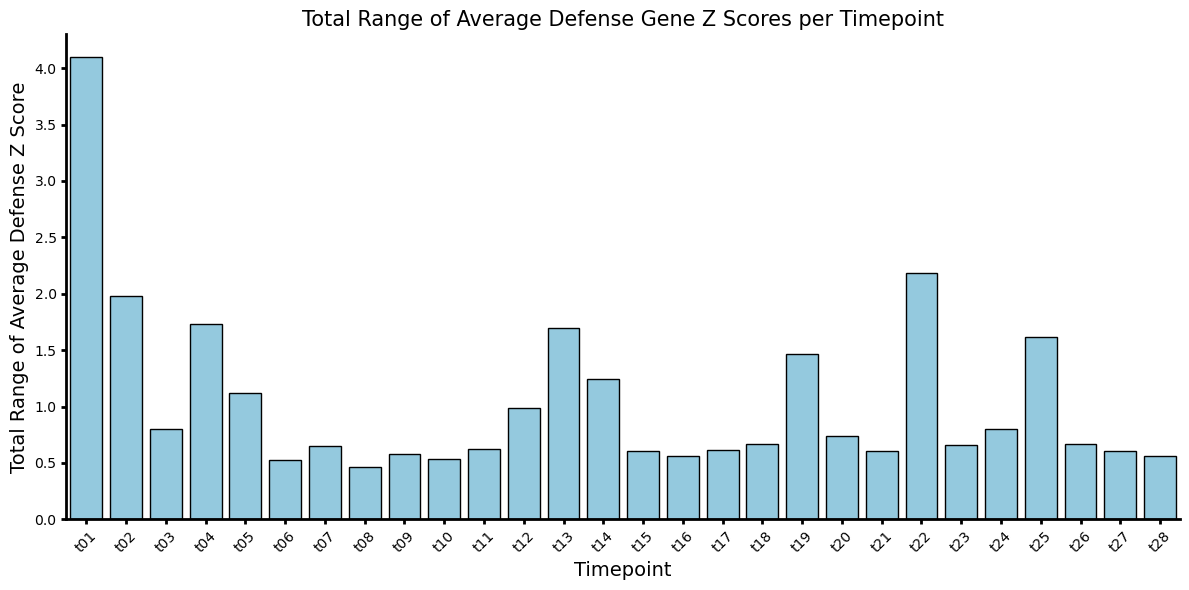

In [22]:
# Calculate the total range (max - min) within each timepoint
range_df = (
    plotting_df.groupby("timepoint")["Summed Defense Z Score"]
    .agg(lambda x: x.max() - x.min())
    .reset_index(name="Total Range")
)

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("white")
sns.barplot(
    data=range_df,
    x="timepoint",
    y="Total Range",
    order=sorted(range_df["timepoint"].unique()),
    ax=ax,
    color="skyblue",
    edgecolor="black",
)
plt.xlabel("Timepoint", fontsize=14)
plt.ylabel("Total Range of Average Defense Z Score", fontsize=14)
plt.title("Total Range of Average Defense Gene Z Scores per Timepoint", fontsize=15)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2, labelsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()